Step 1: GPU Availability Check and Ultralytics Installation

In [1]:

!nvidia-smi
!pip install -q ultralytics


Wed Oct 21 07:09:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Step 2: Mount Google Drive and Locate the Dataset

In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Step 3: Locate the CivicResolve Dataset Configuration

---



In [4]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")
matches = list(drive_root.rglob("04_Final_YOLO_Dataset/data.yaml"))

print("Matching dataset configurations:", len(matches))

for path in matches:
    print(path)


Matching dataset configurations: 1
/content/drive/MyDrive/CivicResolve_Datasets/04_Final_YOLO_Dataset/data.yaml


Step 4: Verify Dataset Structure and Configuration Files

In [5]:

from pathlib import Path
import yaml

dataset_dir = Path(
    "/content/drive/MyDrive/CivicResolve_Datasets/04_Final_YOLO_Dataset"
)
yaml_path = dataset_dir / "data.yaml"

# Check dataset folders
for split in ["train", "val", "test"]:
    image_dir = dataset_dir / "images" / split
    label_dir = dataset_dir / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ]
    labels = list(label_dir.glob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} label files")

# Fix dataset paths
config = yaml.safe_load(yaml_path.read_text())

config["path"] = str(dataset_dir)
config["train"] = "images/train"
config["val"] = "images/val"
config["test"] = "images/test"

yaml_path.write_text(yaml.safe_dump(config, sort_keys=False))

print("\nUpdated data.yaml:")
print(yaml_path.read_text())


train: 5625 images, 5625 label files
val: 752 images, 752 label files
test: 320 images, 320 label files

Updated data.yaml:
path: /content/drive/MyDrive/CivicResolve_Datasets/04_Final_YOLO_Dataset
train: images/train
val: images/val
test: images/test
names:
  0: fallen_tree
  1: garbage
  2: pothole
  3: streetlight
  4: water_leak



Step 5: Verify Dataset Images and Label Files

In [7]:

from pathlib import Path
import time

dataset_dir = Path(
    "/content/drive/MyDrive/CivicResolve_Datasets/04_Final_YOLO_Dataset"
)

for split in ["train", "val", "test"]:
    folder = dataset_dir / "images" / split
    start = time.time()
    count = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    )
    print(f"{split}: {count} images | {time.time()-start:.1f} seconds")


train: 5625 images | 2.9 seconds
val: 752 images | 0.2 seconds
test: 320 images | 0.1 seconds


Step 6: Copy Dataset to Colab Local Storage

In [8]:

import shutil
from pathlib import Path

source = Path(
    "/content/drive/MyDrive/CivicResolve_Datasets/04_Final_YOLO_Dataset"
)
destination = Path("/content/CivicResolve_Dataset")

if destination.exists():
    shutil.rmtree(destination)

print("Copying dataset to Colab local storage...")
shutil.copytree(source, destination)

print("Copy complete:", destination.exists())
print("Dataset YAML exists:", (destination / "data.yaml").exists())


Copying dataset to Colab local storage...
Copy complete: True
Dataset YAML exists: True


Step 7: Update the YOLO Dataset Configuration (data.yaml)

In [9]:

import yaml

yaml_path = destination / "data.yaml"
config = yaml.safe_load(yaml_path.read_text())

config["path"] = str(destination)
config["train"] = "images/train"
config["val"] = "images/val"
config["test"] = "images/test"

yaml_path.write_text(yaml.safe_dump(config, sort_keys=False))

for split in ["train", "val", "test"]:
    folder = destination / "images" / split
    print(split, "images:", len(list(folder.iterdir())))

print("\nUpdated YAML:")
print(yaml_path.read_text())


train images: 5625
val images: 752
test images: 320

Updated YAML:
path: /content/CivicResolve_Dataset
train: images/train
val: images/val
test: images/test
names:
  0: fallen_tree
  1: garbage
  2: pothole
  3: streetlight
  4: water_leak



Step 8: Train the YOLOv8n Model

In [10]:

from ultralytics import YOLO
import torch

print("GPU available:", torch.cuda.is_available())
print("Dataset:", yaml_path)

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=416,
    batch=8,
    workers=2,
    cache=False,
    device=0,
    project="/content/civicresolve_runs",
    name="civicresolve_trial2",
    seed=42,
    plots=True
)


GPU available: True
Dataset: /content/CivicResolve_Dataset/data.yaml
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CivicResolve_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, mul

Step 9: Review Training Results and Performance Metrics

In [11]:

from pathlib import Path
import shutil

best_path = Path(
    "/content/civicresolve_runs/civicresolve_trial2/weights/best.pt"
)

destination = Path(
    "/content/drive/MyDrive/CivicResolve_best.pt"
)

if best_path.exists():
    shutil.copy2(best_path, destination)
    print("SUCCESS: Model saved to Google Drive!")
    print("Location:", destination)
    print("Size (MB):", round(destination.stat().st_size / (1024 * 1024), 2))
else:
    print("best.pt not found. Searching for saved model files...")
    for path in Path("/content/civicresolve_runs").rglob("best.pt"):
        print(path)


SUCCESS: Model saved to Google Drive!
Location: /content/drive/MyDrive/CivicResolve_best.pt
Size (MB): 6.17


Step 10: Load the Trained Model

In [12]:

from ultralytics import YOLO

model_path = "/content/drive/MyDrive/CivicResolve_best.pt"
trained_model = YOLO(model_path)

print("Model loaded successfully!")
print("Detected classes:", trained_model.names)


Model loaded successfully!
Detected classes: {0: 'fallen_tree', 1: 'garbage', 2: 'pothole', 3: 'streetlight', 4: 'water_leak'}


Step 11: Test the Model on a Sample Civic-Issue Image

In [13]:

from google.colab import files

uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

print("Uploaded image:", image_path)


Saving img0301.jpg to img0301.jpg
Uploaded image: img0301.jpg


Step 12: Locate the Trained Model Weights (best.pt)


image 1/1 /content/img0301.jpg: 416x416 1 garbage, 9.0ms
Speed: 1.3ms preprocess, 9.0ms inference, 1.4ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/detect/predict
Detected classes: {0: 'fallen_tree', 1: 'garbage', 2: 'pothole', 3: 'streetlight', 4: 'water_leak'}
Boxes detected: 1


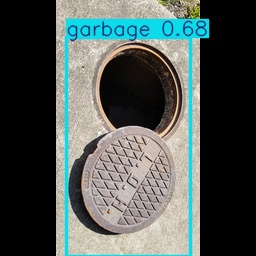

In [14]:

from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image

model_path = "/content/drive/MyDrive/CivicResolve_best.pt"

if not Path(model_path).exists():
    raise FileNotFoundError(
        "Model not found. Complete Step 9 to save best.pt first."
    )

model = YOLO(model_path)

results = model.predict(
    source=image_path,
    imgsz=416,
    conf=0.25,
    save=True
)

print("Detected classes:", model.names)

for result in results:
    print("Boxes detected:", len(result.boxes))
    output_path = Path(result.save_dir) / Path(image_path).name
    if output_path.exists():
        display(Image(filename=str(output_path)))


Step 13: Verify the Trained Model File

In [15]:

from pathlib import Path
import shutil

prediction_dir = Path("/content/runs/detect/predict")
drive_output = Path("/content/drive/MyDrive/CivicResolve_Predictions")

drive_output.mkdir(parents=True, exist_ok=True)

images = [
    p for p in prediction_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

if images:
    for image in images:
        destination = drive_output / image.name
        shutil.copy2(image, destination)
        print("Saved:", destination)
else:
    print("No images found. Check the prediction output directory.")


Saved: /content/drive/MyDrive/CivicResolve_Predictions/img0301.jpg


Step 14: Save the Trained Model to Google Drive

In [16]:

from pathlib import Path

model_path = Path("/content/drive/MyDrive/CivicResolve_best.pt")

if model_path.exists():
    print("✅ Model found!")
    print("Path:", model_path)
    print("Size:", round(model_path.stat().st_size / (1024 * 1024), 2), "MB")
else:
    print("❌ Model not found. Searching for best.pt...")
    for p in Path("/content/civicresolve_runs").rglob("best.pt"):
        print(p)


✅ Model found!
Path: /content/drive/MyDrive/CivicResolve_best.pt
Size: 6.17 MB


Step 15 — Download the Trained Model

In [17]:

from google.colab import files

files.download("/content/drive/MyDrive/CivicResolve_best.pt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 16 — Move the Model into Your VS Code Project

In [18]:
from pathlib import Path

for p in Path("/content").rglob("best.pt"):
    print(p)

/content/civicresolve_runs/civicresolve_trial2/weights/best.pt


Step 17 — Update the Model Path

In [19]:
import shutil
from pathlib import Path

source = Path(
    "/content/civicresolve_runs/civicresolve_trial2/weights/best.pt"
)

destination = Path(
    "/content/drive/MyDrive/CivicResolve_best.pt"
)

if source.exists():
    shutil.copy2(source, destination)
    print("Model saved to Google Drive:", destination)
else:
    print("Source not found. Use the path printed in Step 1.")

Model saved to Google Drive: /content/drive/MyDrive/CivicResolve_best.pt
